In [46]:
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim

import torchvision
from torchvision.datasets import CIFAR10

# Datasets and DataLoader

In [56]:
from torch.utils.data import DataLoader
import torchvision.transforms as transforms # utility used for image transformation

# Data Augmentation & Normalization for Training
# RandomCrop & RandomHorizontalFlip artificially broaden the variety of training samples to suppress overfitting.
train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(), # converts the image to tensor, and automatically scales the image
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)) # These are already set values to bring the image range of CIFAR10 to [-1,1]
])

# Deterministic Normalization for Testing/Validation (no augmentation for fair evaluation)
test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

trainset = CIFAR10(root="./data", train=True, download=True, transform=train_transform)
testset = CIFAR10(root="./data", train=False, download=True, transform=test_transform)


In [57]:
trainloader = DataLoader(trainset, batch_size = 64, shuffle = True)
testloader = DataLoader(testset, batch_size = 64)

# Building the CNN

In [58]:
class CNN(nn.Module):
    def __init__(self):
        super(CNN, self).__init__()

        # Convolutional Layers with Batch Normalization, ReLU, Maxpooling, and Spatial Dropout
        self.conv_layers = nn.Sequential(
            # Block 1
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2, 2), # kernel size = 2, stride = 2
            nn.Dropout2d(0.25),

            # Block 2
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Dropout2d(0.25),

            # Block 3
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Dropout2d(0.25)
        )

        # Fully-Connected layers with Dropout
        self.fc_layers = nn.Sequential(
            nn.Linear(4 * 4 * 128, 256),
            nn.ReLU(),
            nn.Dropout(0.5),

            nn.Linear(256, 10) # 10 output classes
        )

    def forward(self, x):
        x = self.conv_layers(x)
        x = x.view(x.size(0), -1)  # standard code for flattening the matrix in PyTorch
        x = self.fc_layers(x)      # Final output logits

        return x


In [59]:
model = CNN()

In [60]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters())

## Training the CNN

In [ ]:
epochs = 10
train_losses = []
val_losses = []

for epoch in range(epochs):
    model.train()
    epoch_running_loss = 0.0
    
    for images, labels in trainloader:
        optimizer.zero_grad()

        output = model(images) # Fwd propagation
        loss = criterion(output, labels) # loss function
        loss.backward()   # Backpropagation(gradient calculation)
        optimizer.step()  # updates the params

        epoch_running_loss += loss.item()  # converts the tensor to python float

    epoch_train_loss = epoch_running_loss/len(trainloader)   
    train_losses.append(epoch_train_loss)

    # Validation
    model.eval()
    val_running_loss = 0.0

    with torch.no_grad():
        for images, labels in testloader:
            output = model(images)
            loss = criterion(output, labels)
            val_running_loss += loss.item()

    epoch_val_loss = val_running_loss/len(testloader)
    val_losses.append(epoch_val_loss)

    print(f"epoch {epoch+1}/{epochs} ==> train loss = {epoch_train_loss:.4f} & val loss = {epoch_val_loss:.4f}")


epoch 1/10 ==> train loss = 1.3969138805823558 & val loss = 1.0906195640563965
epoch 2/10 ==> train loss = 0.9568395591757791 & val loss = 0.8914200067520142
epoch 3/10 ==> train loss = 0.7689658219323439 & val loss = 0.806290328502655
epoch 4/10 ==> train loss = 0.6455693987324415 & val loss = 0.7810691595077515
epoch 5/10 ==> train loss = 0.5389886100769348 & val loss = 0.7217108607292175
epoch 6/10 ==> train loss = 0.44706801740485996 & val loss = 0.7899271845817566
epoch 7/10 ==> train loss = 0.3633983437152927 & val loss = 0.8460583686828613
epoch 8/10 ==> train loss = 0.28599442015675935 & val loss = 0.8567219376564026
epoch 9/10 ==> train loss = 0.22097011230638264 & val loss = 0.9958966374397278
epoch 10/10 ==> train loss = 0.18163386855960426 & val loss = 1.03415048122406


## Evaluation of the Model

In [ ]:
correct_labels = 0
total_labels = 0

model.eval()

with torch.no_grad():
    for images, labels in testloader:
        outputs = model(images)
        _, predicted = torch.max(outputs, 1)

        correct_labels += (predicted == labels).sum().item()
        total_labels += labels.size(0)

print(f" accuracy = {correct_labels/total_labels * 100}")

 accuracy = 75.18


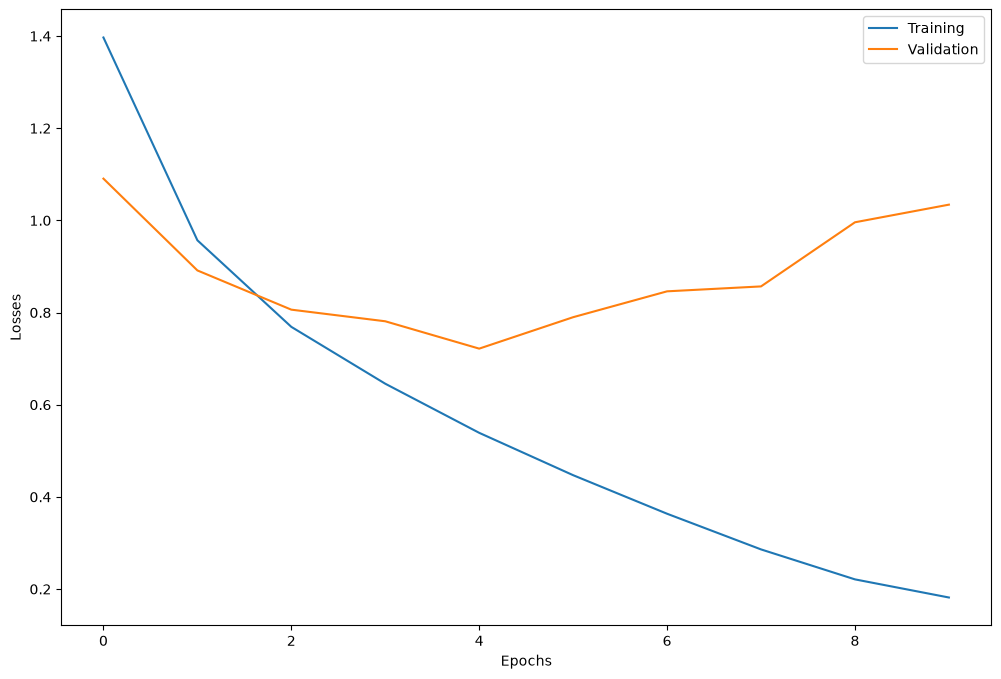

In [64]:
# plotting the loss

import matplotlib.pyplot as plt

loss_df = pd.DataFrame({
    "Training Loss": train_losses,
    "Validation Loss" : val_losses
}
)

plt.figure(figsize = (12,8))
plt.plot(loss_df["Training Loss"], label = "Training")
plt.plot(loss_df["Validation Loss"], label = "Validation")

plt.xlabel("Epochs")
plt.ylabel("Losses")

plt.legend()

In [65]:
import os

os.makedirs("weights", exist_ok=True)
torch.save(model.state_dict(), "weights/cifar10_cnn.pth")
print("Model weights successfully saved to weights/cifar10_cnn.pth")

Model weights successfully saved to weights/cifar10_cnn.pth
